## 1. Data Preparation

In [40]:

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [41]:
dataset_path = "/kaggle/input/dataset-x-fake-profile-zip/dataset_x_fake_profile/"
print(f"📂 Dataset path: {dataset_path}")



📂 Dataset path: /kaggle/input/dataset-x-fake-profile-zip/dataset_x_fake_profile/


In [42]:
import os

dataset_path = "/kaggle/input/dataset-x-fake-profile-zip/dataset_x_fake_profile/"
base_len = len(dataset_path)
total_images = 0

for root, dirs, files in os.walk(dataset_path):
    num_images = len([f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    if num_images > 0:
        short_path = root[base_len:]
        total_images += num_images
        print(f"📁 Folder: {short_path} - 🖼️ Number of images: {num_images}")

print("\n📊 Total number of images in the dataset:", total_images)


📁 Folder: validation/bot - 🖼️ Number of images: 250
📁 Folder: validation/real - 🖼️ Number of images: 250
📁 Folder: validation/cyborg - 🖼️ Number of images: 250
📁 Folder: validation/verified - 🖼️ Number of images: 250
📁 Folder: test/bot - 🖼️ Number of images: 1000
📁 Folder: test/real - 🖼️ Number of images: 1000
📁 Folder: test/cyborg - 🖼️ Number of images: 1000
📁 Folder: test/verified - 🖼️ Number of images: 1000
📁 Folder: train/bot - 🖼️ Number of images: 2500
📁 Folder: train/real - 🖼️ Number of images: 2500
📁 Folder: train/cyborg - 🖼️ Number of images: 2500
📁 Folder: train/verified - 🖼️ Number of images: 2500

📊 Total number of images in the dataset: 15000


In [43]:
"""import os
import cv2
import numpy as np
from tqdm import tqdm
from multiprocessing import Pool, cpu_count

input_root = "/kaggle/input/dataset-x-fake-profile-zip/dataset_x_fake_profile"
output_root = "/kaggle/working/dataset_x_normalized"

def min_max_normalization(img):
    img = img.astype(np.float32)
    min_val = np.min(img, axis=(0, 1), keepdims=True)
    max_val = np.max(img, axis=(0, 1), keepdims=True)
    range_val = max_val - min_val
    range_val[range_val == 0] = 1  
    normalized_img = (img - min_val) / range_val * 255
    return np.clip(normalized_img, 0, 255).astype(np.uint8)

def process_image(args):
    input_path, output_path, normalization_func = args
    img = cv2.imread(input_path)
    if img is None:
        return False  

    norm_img = normalization_func(img)
    if len(norm_img.shape) == 2:
        norm_img = cv2.cvtColor(norm_img, cv2.COLOR_GRAY2BGR)

    cv2.imwrite(output_path, norm_img)
    return True

def process_and_save_images(normalization_func, technique_name):
    for split in ["train", "test", "validation"]:
        for category in ["verified", "real", "cyborg", "bot"]:
            input_dir = os.path.join(input_root, split, category)
            output_dir = os.path.join(output_root, technique_name, split, category)
            os.makedirs(output_dir, exist_ok=True)

            images = os.listdir(input_dir)
            total_images = len(images)

            args_list = []
            for img_name in images:
                input_path = os.path.join(input_dir, img_name)
                output_path = os.path.join(output_dir, img_name)
                args_list.append((input_path, output_path, normalization_func))

            with Pool(processes=cpu_count()) as pool:
                results = list(tqdm(pool.imap_unordered(process_image, args_list), total=total_images,
                                    desc=f"🔄 {split}/{category} ({technique_name})", unit="image"))

    print(f"✅ {technique_name} normalization applied and images saved successfully!")

process_and_save_images(min_max_normalization, "min_max")"""


'import os\nimport cv2\nimport numpy as np\nfrom tqdm import tqdm\nfrom multiprocessing import Pool, cpu_count\n\ninput_root = "/kaggle/input/dataset-x-fake-profile-zip/dataset_x_fake_profile"\noutput_root = "/kaggle/working/dataset_x_normalized"\n\ndef min_max_normalization(img):\n    img = img.astype(np.float32)\n    min_val = np.min(img, axis=(0, 1), keepdims=True)\n    max_val = np.max(img, axis=(0, 1), keepdims=True)\n    range_val = max_val - min_val\n    range_val[range_val == 0] = 1  \n    normalized_img = (img - min_val) / range_val * 255\n    return np.clip(normalized_img, 0, 255).astype(np.uint8)\n\ndef process_image(args):\n    input_path, output_path, normalization_func = args\n    img = cv2.imread(input_path)\n    if img is None:\n        return False  \n\n    norm_img = normalization_func(img)\n    if len(norm_img.shape) == 2:\n        norm_img = cv2.cvtColor(norm_img, cv2.COLOR_GRAY2BGR)\n\n    cv2.imwrite(output_path, norm_img)\n    return True\n\ndef process_and_save_

In [44]:
import os
import torch

base_data_dir = "/kaggle/working/dataset_x_normalized/min_max"  
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

splits = ["train", "validation", "test"]
categories = ["verified", "real", "cyborg", "bot"]

for split in splits:
    for category in categories:
        path = os.path.join(base_data_dir, split, category)
        if not os.path.exists(path):
            print(f"⚠️ Warning: Folder {path} does not exist!")
        else:
            print(f"📂 Path exists: {path}")

print(f"\n🖥️ Device in use: {device}")

print(f"📂 Test data path: {os.path.join(base_data_dir, 'test')}")


📂 Path exists: /kaggle/working/dataset_x_normalized/min_max/train/verified
📂 Path exists: /kaggle/working/dataset_x_normalized/min_max/train/real
📂 Path exists: /kaggle/working/dataset_x_normalized/min_max/train/cyborg
📂 Path exists: /kaggle/working/dataset_x_normalized/min_max/train/bot
📂 Path exists: /kaggle/working/dataset_x_normalized/min_max/validation/verified
📂 Path exists: /kaggle/working/dataset_x_normalized/min_max/validation/real
📂 Path exists: /kaggle/working/dataset_x_normalized/min_max/validation/cyborg
📂 Path exists: /kaggle/working/dataset_x_normalized/min_max/validation/bot
📂 Path exists: /kaggle/working/dataset_x_normalized/min_max/test/verified
📂 Path exists: /kaggle/working/dataset_x_normalized/min_max/test/real
📂 Path exists: /kaggle/working/dataset_x_normalized/min_max/test/cyborg
📂 Path exists: /kaggle/working/dataset_x_normalized/min_max/test/bot

🖥️ Device in use: cuda
📂 Test data path: /kaggle/working/dataset_x_normalized/min_max/test


## 2. Image Transformations


In [45]:
from torchvision import transforms

transform_train = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0, translate=(0.2, 0.2), shear=10),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.RandomGrayscale(p=0.1),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.4),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_val_test = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("✅ Image transformations set successfully!")


✅ Image transformations set successfully!


## 3. Data Loading

In [46]:
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
import torch
import os

base_data_dir ="/kaggle/working/dataset_x_normalized/min_max"

train_path = os.path.join(base_data_dir, "train")
validation_path = os.path.join(base_data_dir, "validation")
test_path = os.path.join(base_data_dir, "test")

assert os.path.exists(train_path), f"❌ Train path does not exist: {train_path}"
assert os.path.exists(validation_path), f"❌ Validation path does not exist: {validation_path}"
assert os.path.exists(test_path), f"❌ Test path does not exist: {test_path}"

train_dataset = ImageFolder(root=train_path, transform=transform_train)
validation_dataset = ImageFolder(root=validation_path, transform=transform_val_test)
test_dataset = ImageFolder(root=test_path, transform=transform_val_test)

print("✅ Data loaded successfully!")
print(f"🔹 Number of training images: {len(train_dataset)}")
print(f"🔹 Number of validation images: {len(validation_dataset)}")
print(f"🔹 Number of test images: {len(test_dataset)}")

use_gpu = torch.cuda.is_available()
num_workers = min(8, os.cpu_count() // 2) if use_gpu else min(4, os.cpu_count() // 4)
pin_memory = use_gpu
prefetch_factor = 4 if num_workers > 0 else None

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True,
    num_workers=num_workers, pin_memory=pin_memory,
    persistent_workers=(use_gpu and num_workers > 0), prefetch_factor=prefetch_factor,
    drop_last=False
)

validation_loader = DataLoader(
    validation_dataset, batch_size=32, shuffle=False,
    num_workers=num_workers, pin_memory=pin_memory,
    persistent_workers=(use_gpu and num_workers > 0), prefetch_factor=prefetch_factor
)

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False,
    num_workers=num_workers, pin_memory=pin_memory,
    persistent_workers=(use_gpu and num_workers > 0), prefetch_factor=prefetch_factor
)

print("🚀 DataLoaders are ready to use!")


✅ Data loaded successfully!
🔹 Number of training images: 10000
🔹 Number of validation images: 1000
🔹 Number of test images: 4000
🚀 DataLoaders are ready to use!


## 4. Model Architecture

In [47]:
"""import torch
import torch.nn as nn
from torchvision import models

weights_path = "/kaggle/input/resnet50-11ad3fa6-pth/resnet50-11ad3fa6.pth"
model = models.resnet50()
model.load_state_dict(torch.load(weights_path, map_location="cuda" if torch.cuda.is_available() else "cpu"))

for param in model.parameters():
    param.requires_grad = False

for layer in [model.layer2, model.layer3, model.layer4]:
    for param in layer.parameters():
        param.requires_grad = True

num_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Flatten(),
    nn.Linear(num_features, 1024),
    nn.BatchNorm1d(1024),
    nn.LeakyReLU(0.1, inplace=True),
    nn.Dropout(0.25),
    nn.Linear(1024, 512),
    nn.BatchNorm1d(512),
    nn.LeakyReLU(0.1, inplace=True),
    nn.Dropout(0.15),
    nn.Linear(512, 4)
)

for param in model.fc.parameters():
    param.requires_grad = True

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model = model.to(device)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"✅ Number of trainable parameters: {trainable_params:,}")
print(model.fc)
print("✅ Model is successfully prepared for training 🎯")"""


'import torch\nimport torch.nn as nn\nfrom torchvision import models\n\nweights_path = "/kaggle/input/resnet50-11ad3fa6-pth/resnet50-11ad3fa6.pth"\nmodel = models.resnet50()\nmodel.load_state_dict(torch.load(weights_path, map_location="cuda" if torch.cuda.is_available() else "cpu"))\n\nfor param in model.parameters():\n    param.requires_grad = False\n\nfor layer in [model.layer2, model.layer3, model.layer4]:\n    for param in layer.parameters():\n        param.requires_grad = True\n\nnum_features = model.fc.in_features\nmodel.fc = nn.Sequential(\n    nn.Flatten(),\n    nn.Linear(num_features, 1024),\n    nn.BatchNorm1d(1024),\n    nn.LeakyReLU(0.1, inplace=True),\n    nn.Dropout(0.25),\n    nn.Linear(1024, 512),\n    nn.BatchNorm1d(512),\n    nn.LeakyReLU(0.1, inplace=True),\n    nn.Dropout(0.15),\n    nn.Linear(512, 4)\n)\n\nfor param in model.fc.parameters():\n    param.requires_grad = True\n\ndevice = torch.device("mps" if torch.backends.mps.is_available() else "cpu")\nmodel = mode

## 5. Optimizer & Scheduler


In [48]:
"""
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                        lr=3e-4, weight_decay=1e-4, eps=1e-8)

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=0.003,
    steps_per_epoch=len(train_loader),
    epochs=10,
    pct_start=0.2,
    anneal_strategy='cos',
    div_factor=25,
    final_div_factor=1000
)
"""


"\nimport torch.nn as nn\nimport torch.optim as optim\n\ncriterion = nn.CrossEntropyLoss()\n\noptimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),\n                        lr=3e-4, weight_decay=1e-4, eps=1e-8)\n\nscheduler = torch.optim.lr_scheduler.OneCycleLR(\n    optimizer,\n    max_lr=0.003,\n    steps_per_epoch=len(train_loader),\n    epochs=10,\n    pct_start=0.2,\n    anneal_strategy='cos',\n    div_factor=25,\n    final_div_factor=1000\n)\n"

In [49]:
import os
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import random
import copy


In [50]:
#optimizer_path = "/kaggle/working/HungerGamesSearch.py"

#os.makedirs(os.path.dirname(optimizer_path), exist_ok=True)


## 6. Hyperparameter Optimization


### 6.1 Algo Optimizer

In [51]:
import random
import numpy as np
import os
import time


class ShellGameOptimization:
    def __init__(self, fitness_function, bounds, num_individuals=3, max_iter=2, base_save_path="/kaggle/working"):
        self.fitness_function = fitness_function
        self.bounds = bounds
        self.num_individuals = num_individuals
        self.dim = len(bounds)
        self.max_iter = max_iter
        self.base_save_path = base_save_path

    def initialize_population(self):
        population = []
        for _ in range(self.num_individuals):
            individual = [random.uniform(*self.bounds[i]) for i in range(self.dim)]
            population.append(individual)
        return population

    def evaluate_population(self, population, iteration):
        fitness = []
        for i, individual in enumerate(population):
            score, _ = self.fitness_function(individual, iteration, i)
            fitness.append(score)
        return fitness

    def optimize(self):
        history = []

        total_start_time = time.time()

        population = self.initialize_population()
        fitness = self.evaluate_population(population, iteration=0)
        best_idx = np.argmin(fitness)
        best_individual = population[best_idx]
        best_score = fitness[best_idx]

        for iteration in range(1, self.max_iter + 1):
            print(f"\n🎯 SGO Iteration {iteration}/{self.max_iter}")
            new_population = []

            for i in range(self.num_individuals):
                if i == best_idx:
                    new_population.append(best_individual)  
                    continue

                new_individual = []
                for d in range(self.dim):
                    r1 = random.uniform(0.5, 1.0)
                    r2 = random.uniform(-0.1, 0.1)  
                    move = r1 * (best_individual[d] - population[i][d]) + r2
                    candidate = population[i][d] + move

                    lower, upper = self.bounds[d]
                    candidate = min(max(candidate, lower), upper)
                    new_individual.append(candidate)

                new_population.append(new_individual)

            population = new_population
            fitness = self.evaluate_population(population, iteration)

            current_best_idx = np.argmin(fitness)
            if fitness[current_best_idx] < best_score:
                best_score = fitness[current_best_idx]
                best_individual = population[current_best_idx]

            history.append(best_score)
            print(f"✅ Best score so far: {-best_score:.4f}")

        total_hpo_time = time.time() - total_start_time
        hours = int(total_hpo_time // 3600)
        minutes = int((total_hpo_time % 3600) // 60)
        seconds = int(total_hpo_time % 60)

        os.makedirs(self.base_save_path, exist_ok=True)
        results_file = os.path.join(self.base_save_path, "training_results.txt")
        with open(results_file, "a", encoding="utf-8") as f:
            f.write(f"\n🧠 ✅ Total HPO Time: {hours:02d}:{minutes:02d}:{seconds:02d} (hh:mm:ss)\n")
            f.write("=" * 60 + "\n")

        return best_individual, best_score


In [52]:
import torch.nn as nn
from torchvision import models

class CustomResNet50(nn.Module):
    def __init__(self, num_classes=4, dropout_rate=0.3):
        super(CustomResNet50, self).__init__()
        
        weights_path = "/kaggle/input/resnet50-11ad3fa6-pth/resnet50-11ad3fa6.pth"
        base_model = models.resnet50()
        base_model.load_state_dict(torch.load(weights_path, map_location="cuda" if torch.cuda.is_available() else "cpu"))

        for param in base_model.parameters():
            param.requires_grad = False

        for layer in [base_model.layer2, base_model.layer3, base_model.layer4]:
            for param in layer.parameters():
                param.requires_grad = True

        num_features = base_model.fc.in_features
        base_model.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(num_features, 1024),
            nn.BatchNorm1d(1024),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Dropout(dropout_rate),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Dropout(dropout_rate / 2),  
            nn.Linear(512, num_classes)
        )

        self.model = base_model

    def forward(self, x):
        return self.model(x)


### 6.2 Fitness Function

## 7. Final Training


In [53]:
def fitness_func(hyperparams, iteration, individual):
    import os
    import time
    import random
    import torch
    import torch.nn as nn
    from torch.utils.data import Subset, DataLoader

    lr, weight_decay, eps, batch_size, dropout_rate, T_max, num_epochs = hyperparams

    subset_size = 2000
    random.seed(42)
    indices = random.sample(range(len(train_dataset)), subset_size)
    train_subset = Subset(train_dataset, indices)
    train_loader = DataLoader(train_subset, batch_size=int(batch_size), shuffle=True)

    model_copy = CustomResNet50(dropout_rate=dropout_rate).to(device)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model_copy.parameters()),
        lr=lr, weight_decay=weight_decay, eps=eps
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=int(T_max))
    criterion = nn.CrossEntropyLoss()

    log_file_path = os.path.join(base_save_path, "training_results.txt")

    start_time = time.time()

    train_model(
        model=model_copy,
        train_loader=train_loader,
        val_loader=validation_loader,
        criterion=criterion,
        optimizer=optimizer,
        scheduler=scheduler,
        num_epochs=int(num_epochs),
        save_path=base_save_path,
        log_results=True,
        device=device,
        log_to_csv=False,
        best_batch_size=int(batch_size),
        best_dropout_rate=dropout_rate,
        best_T_max=int(T_max),
        best_num_epochs=int(num_epochs),
        agent_id=individual,
        start_epoch=1,
        log_file_path=log_file_path,
        iteration=iteration
    )

    training_time = time.time() - start_time

    val_loss, val_acc = validate_model(model_copy, validation_loader, criterion, device)

    return -val_acc, val_loss


### 7.1 Environment Setup & Paths

In [54]:
from datetime import datetime
import os
import torch
import gc
from torch.cuda.amp import GradScaler

base_save_path = "/kaggle/working"
best_model_path = os.path.join(base_save_path, "best_model.pth")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

start_epoch = 1
model = CustomResNet50(dropout_rate=0.3).to(device)

if os.path.exists(best_model_path):
    print("✅ Loading the best saved model...")
    model.load_state_dict(torch.load(best_model_path, map_location=device))
    model.to(device)

    training_log = os.path.join(base_save_path, "training_results.txt")
    if os.path.exists(training_log):
        with open(training_log, "r", encoding="utf-8") as f:
            lines = f.readlines()
            for line in reversed(lines):
                if "Epoch" in line and "/" in line:
                    try:
                        start_epoch = int(line.split(" ")[1].split("/")[0]) + 1
                        break
                    except:
                        pass

    print(f"🚀 Starting training from Epoch {start_epoch} using the best saved model.")
else:
    print("🚀 Starting training from scratch.")

optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-3)
scaler = GradScaler() if torch.cuda.is_available() else None


🚀 Starting training from scratch.


### 7.2 Main Training Function

In [55]:
from tqdm import tqdm
import torch
import gc
import os

def train_one_epoch(
    model, train_loader, optimizer, criterion, device, epoch, num_epochs,
    use_amp=False, scaler=None,
):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    total_batches = len(train_loader)

    loop = tqdm(train_loader, total=total_batches, desc=f"🚀 Epoch {epoch}/{num_epochs}", unit="batch", leave=False)

    for batch_idx, (inputs, targets) in enumerate(loop):
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()

        with torch.cuda.amp.autocast(enabled=use_amp):
            outputs = model(inputs)
            loss = criterion(outputs, targets)

        if use_amp and scaler is not None:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()

        avg_loss = running_loss / total
        accuracy = 100. * correct / total
        loop.set_postfix(loss=f"{avg_loss:.4f}", acc=f"{accuracy:.2f}%")

        if use_amp and batch_idx % 10 == 0:
            del inputs, targets, outputs, loss
            torch.cuda.empty_cache()
            gc.collect()

    avg_loss = running_loss / total
    accuracy = 100. * correct / total

    return avg_loss, accuracy


## 8. Evaluation & Logging

In [56]:
import os
import gc
import csv
from datetime import datetime
import torch

def train_model(
    model, train_loader, val_loader, criterion, optimizer, scheduler,
    num_epochs, save_path="/kaggle/working", use_amp=True, log_results=True,
    start_epoch=1, scaler=None, device=None, test_loader=None,
    log_to_csv=True, agent_id=None, iteration=None, log_file_path=None,
    best_batch_size=None, best_dropout_rate=None, best_T_max=None, best_num_epochs=None
):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    results_dir = os.path.join(save_path)
    os.makedirs(results_dir, exist_ok=True)

    results_file = log_file_path if log_file_path else os.path.join(results_dir, "training_results.txt")
    csv_log_path = os.path.join(results_dir, "training_log.csv")
    best_model_path = os.path.join(save_path, "best_model.pth")

    if log_to_csv and os.path.exists(csv_log_path):
        print(f"🧹 Removing old training log: {csv_log_path}")
        os.remove(csv_log_path)

    if log_results and not os.path.exists(results_file):
        with open(results_file, "w", encoding="utf-8") as f:
            f.write("📌 Training Results Log\n" + "=" * 50 + "\n\n")

    if log_to_csv and not os.path.exists(csv_log_path):
        with open(csv_log_path, "w", newline="", encoding="utf-8") as csvfile:
            writer = csv.writer(csvfile)
            writer.writerow(["Epoch", "Train Loss", "Train Acc", "Val Loss", "Val Acc", "Time"])

    model.to(device)
    patience_counter = 0
    best_validation_loss = float("inf")
    best_validation_acc = 0.0
    early_stopping_patience = 3

    if iteration is not None:
        print(f"\n🎯 Kho-Kho Iteration {iteration}")
    if agent_id is not None:
        print(f"🤖 Agent {agent_id}\n")

    for epoch in range(start_epoch, num_epochs + 1):
        start_time = datetime.now()
        print(f"🔥 Epoch {epoch}/{num_epochs}")
        print("-" * 40)

        train_loss, train_acc = train_one_epoch(
            model, train_loader, optimizer, criterion,
            device, epoch, num_epochs,
            use_amp=use_amp, scaler=scaler
        )

        with torch.no_grad():
            validation_loss, validation_acc = validate_model(model, val_loader, criterion, device)

        elapsed_time = (datetime.now() - start_time).total_seconds()

        if log_to_csv:
            with open(csv_log_path, "a", newline="", encoding="utf-8") as csvfile:
                writer = csv.writer(csvfile)
                writer.writerow([
                    epoch,
                    f"{train_loss:.4f}",
                    f"{train_acc:.2f}",
                    f"{validation_loss:.4f}",
                    f"{validation_acc:.2f}",
                    f"{elapsed_time:.2f}"
                ])

        print("🎯 Training Summary:")
        print(f"    - Train Loss         :  {train_loss:.4f}")
        print(f"    - Train Accuracy     :  {train_acc:.2f}%\n")
        print("🎯 Validation Summary:")
        print(f"    - Validation Loss    :  {validation_loss:.4f}")
        print(f"    - Validation Accuracy:  {validation_acc:.2f}%")

        if validation_loss < best_validation_loss or validation_acc > best_validation_acc:
            best_validation_loss = validation_loss
            best_validation_acc = validation_acc
            patience_counter = 0
            torch.save(model.state_dict(), best_model_path)
        else:
            patience_counter += 1
            print(f"\n⚠️ No improvement for {patience_counter} epochs.")
            if patience_counter >= early_stopping_patience:
                print("\n🛑 Early stopping triggered!")
                break

        if log_results:
            with open(results_file, "a", encoding="utf-8") as f:
                if epoch == start_epoch:
                    if iteration is not None:
                        f.write(f"\n🎯 ShellGameOptimization Iteration {iteration}\n")
                    if agent_id is not None:
                        f.write(f"🤖 Agent {agent_id}\n")
                    # 🧪 سجل الهايبر باراميترز مرة واحدة فقط
                    if any(p is not None for p in [best_batch_size, best_dropout_rate, best_T_max, best_num_epochs]):
                        f.write("🧪 Hyperparameters Used:\n")
                        if best_batch_size is not None:
                            f.write(f"   - Batch Size   : {best_batch_size}\n")
                        if best_dropout_rate is not None:
                            f.write(f"   - Dropout Rate : {best_dropout_rate:.2f}\n")
                        if best_T_max is not None:
                            f.write(f"   - T_max        : {best_T_max}\n")
                        if best_num_epochs is not None:
                            f.write(f"   - Num Epochs   : {best_num_epochs}\n")

                f.write(f"\n🔥 Epoch {epoch}/{num_epochs}\n")
                f.write(f"{'-' * 40}\n")
                f.write("🎯 Training Summary:\n")
                f.write(f"    - Train Loss         :  {train_loss:.4f}\n")
                f.write(f"    - Train Accuracy     :  {train_acc:.2f}%\n")
                f.write("🎯 Validation Summary:\n")
                f.write(f"    - Validation Loss    :  {validation_loss:.4f}\n")
                f.write(f"    - Validation Accuracy:  {validation_acc:.2f}%\n")
                f.write(f"🕒 Epoch Time: {elapsed_time:.2f} seconds\n")
                f.write(f"{'-' * 60}\n")
                f.flush()

        del train_loss, train_acc, validation_loss, validation_acc
        gc.collect()
        torch.cuda.empty_cache()


### 8.1 Validation with TTA

In [57]:

import gc
import torch
from tqdm import tqdm

def tta_predictions(model, images):
    """ Perform Test Time Augmentation (TTA) on images during inference """
    augmentations = [
        images,
        torch.flip(images, [3]),
        torch.rot90(images, 1, [2, 3]),
        torch.flip(images, [2]),
    ]

    with torch.no_grad():
        outputs = [model(aug) for aug in augmentations]
        outputs = torch.stack(outputs)  
        return outputs.mean(dim=0)      

def validate_model(model, val_loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0

    progress_bar = tqdm(val_loader, desc="🧐 Validation", unit="batch", leave=False)

    with torch.no_grad():
        for images, labels in progress_bar:
            images, labels = images.to(device), labels.to(device)

            outputs = tta_predictions(model, images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += batch_size

            avg_loss = running_loss / total
            accuracy = 100.0 * correct / total
            progress_bar.set_postfix(loss=f"{avg_loss:.4f}", acc=f"{accuracy:.2f}%")

    avg_loss = running_loss / total
    accuracy = 100.0 * correct / total

    return avg_loss, accuracy





### 6.3 Run Algo Optimization

In [58]:
bounds = [
    (1e-5, 1e-3),   
    (1e-6, 1e-2),   
    (1e-9, 1e-6),    
    (16, 128),      
    (0.0, 0.5),     
    (10, 100),      
    (5, 10)         
]

optimizer = ShellGameOptimization(
    fitness_function=fitness_func,
    bounds=bounds,
    num_individuals=3,
    max_iter=2,
    base_save_path=base_save_path
)

best_hyperparams, best_score = optimizer.optimize()

best_lr = best_hyperparams[0]
best_weight_decay = best_hyperparams[1]
best_eps = best_hyperparams[2]
best_batch_size = int(best_hyperparams[3])
best_dropout_rate = best_hyperparams[4]
best_T_max = int(best_hyperparams[5])
best_num_epochs = int(best_hyperparams[6])

best_hyperparams_path = os.path.join(base_save_path, "best_hyperparameters.txt")

with open(best_hyperparams_path, "w", encoding="utf-8") as f:
    print("\n🌟 Best Hyperparameters Found:")
    f.write("🌟 Best Hyperparameters Found:\n")

    print(f"🔹 Learning Rate   : {best_lr:.6f}")
    f.write(f"🔹 Learning Rate   : {best_lr:.6f}\n")

    print(f"🔹 Weight Decay    : {best_weight_decay:.6f}")
    f.write(f"🔹 Weight Decay    : {best_weight_decay:.6f}\n")

    print(f"🔹 Epsilon (eps)   : {best_eps:.2e}")
    f.write(f"🔹 Epsilon (eps)   : {best_eps:.2e}\n")

    print(f"🔹 Batch Size      : {best_batch_size}")
    f.write(f"🔹 Batch Size      : {best_batch_size}\n")

    print(f"🔹 Dropout Rate    : {best_dropout_rate:.2f}")
    f.write(f"🔹 Dropout Rate    : {best_dropout_rate:.2f}\n")

    print(f"🔹 T_max           : {best_T_max}")
    f.write(f"🔹 T_max           : {best_T_max}\n")

    print(f"🔹 Num Epochs      : {best_num_epochs}")
    f.write(f"🔹 Num Epochs      : {best_num_epochs}\n")




🎯 Kho-Kho Iteration 0
🤖 Agent 0

🔥 Epoch 1/7
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  0.9160
    - Train Accuracy     :  59.40%

🎯 Validation Summary:
    - Validation Loss    :  0.5326
    - Validation Accuracy:  81.10%
🔥 Epoch 2/7
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  0.5042
    - Train Accuracy     :  79.60%

🎯 Validation Summary:
    - Validation Loss    :  0.2118
    - Validation Accuracy:  93.30%
🔥 Epoch 3/7
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  0.4014
    - Train Accuracy     :  84.45%

🎯 Validation Summary:
    - Validation Loss    :  0.1516
    - Validation Accuracy:  96.80%
🔥 Epoch 4/7
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  0.3093
    - Train Accuracy     :  87.45%

🎯 Validation Summary:
    - Validation Loss    :  0.1068
    - Validation Accuracy:  98.30%
🔥 Epoch 5/7
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  0.3366
    - Train Accuracy     :  86.25%

🎯 Validation Summary:
    - Validation Loss    :  0.1122
    - Validation Accuracy:  97.00%

⚠️ No improvement for 1 epochs.
🔥 Epoch 6/7
----------------------------------------


... (69 outputs left out)

🎯 Training Summary:
    - Train Loss         :  0.2404
    - Train Accuracy     :  89.40%

🎯 Validation Summary:
    - Validation Loss    :  0.0749
    - Validation Accuracy:  98.40%

⚠️ No improvement for 1 epochs.
🔥 Epoch 7/8
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  0.2133
    - Train Accuracy     :  91.10%

🎯 Validation Summary:
    - Validation Loss    :  0.0426
    - Validation Accuracy:  98.90%

⚠️ No improvement for 2 epochs.
🔥 Epoch 8/8
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  0.2270
    - Train Accuracy     :  90.15%

🎯 Validation Summary:
    - Validation Loss    :  0.0506
    - Validation Accuracy:  99.10%

⚠️ No improvement for 3 epochs.

🛑 Early stopping triggered!


✅ Best score so far: 99.4000

🌟 Best Hyperparameters Found:
🔹 Learning Rate   : 0.000212
🔹 Weight Decay    : 0.005019
🔹 Epsilon (eps)   : 6.12e-07
🔹 Batch Size      : 68
🔹 Dropout Rate    : 0.42
🔹 T_max           : 75
🔹 Num Epochs      : 8


In [63]:
import torch
import os
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=best_lr,
    weight_decay=best_weight_decay,
    eps=best_eps
)

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=best_lr,
    steps_per_epoch=len(train_loader),
    epochs=best_num_epochs,
    pct_start=0.2,
    anneal_strategy='cos',
    div_factor=25,
    final_div_factor=1000
)

start_epoch = 1
start_batch = 0

print("🚀 Starting final training from scratch using the best parameters.")



🚀 Starting final training from scratch using the best parameters.


In [64]:

train_model(
    model=model,
    train_loader=train_loader,
    val_loader=validation_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=best_num_epochs,
    save_path=base_save_path,
    start_epoch=start_epoch,
    scaler=scaler,
    device=device,
    log_to_csv=True,
    log_results=False
)



🔥 Epoch 1/8
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  1.2609
    - Train Accuracy     :  41.11%

🎯 Validation Summary:
    - Validation Loss    :  1.0077
    - Validation Accuracy:  58.00%
🔥 Epoch 2/8
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  0.9485
    - Train Accuracy     :  59.78%

🎯 Validation Summary:
    - Validation Loss    :  0.6795
    - Validation Accuracy:  76.40%
🔥 Epoch 3/8
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  0.7487
    - Train Accuracy     :  68.90%

🎯 Validation Summary:
    - Validation Loss    :  0.5485
    - Validation Accuracy:  80.80%
🔥 Epoch 4/8
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  0.6115
    - Train Accuracy     :  75.59%

🎯 Validation Summary:
    - Validation Loss    :  0.4226
    - Validation Accuracy:  87.30%
🔥 Epoch 5/8
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  0.5053
    - Train Accuracy     :  79.59%

🎯 Validation Summary:
    - Validation Loss    :  0.3237
    - Validation Accuracy:  92.00%
🔥 Epoch 6/8
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  0.4224
    - Train Accuracy     :  82.92%

🎯 Validation Summary:
    - Validation Loss    :  0.2520
    - Validation Accuracy:  93.80%
🔥 Epoch 7/8
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  0.3624
    - Train Accuracy     :  85.71%

🎯 Validation Summary:
    - Validation Loss    :  0.1961
    - Validation Accuracy:  96.00%
🔥 Epoch 8/8
----------------------------------------


🎯 Training Summary:
    - Train Loss         :  0.3126
    - Train Accuracy     :  87.81%

🎯 Validation Summary:
    - Validation Loss    :  0.1442
    - Validation Accuracy:  98.20%


### 7.5 Execute Final Training

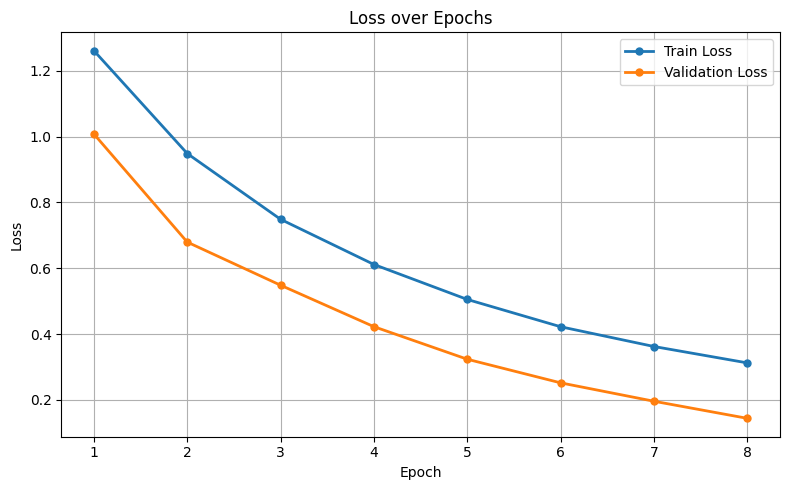

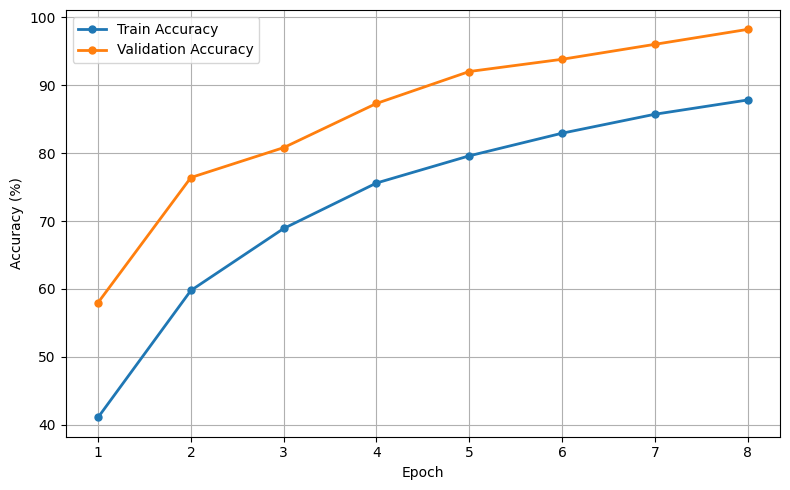

In [65]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/kaggle/working/training_log.csv")

df_plot = df[df["Epoch"] != "FINAL"].copy()
df_plot["Epoch"] = df_plot["Epoch"].astype(int)

train_color = '#1f77b4'  
val_color = '#ff7f0e'    
plt.figure(figsize=(8, 5))
plt.plot(df_plot["Epoch"], df_plot["Train Loss"], '-o', color=train_color, label="Train Loss", linewidth=2, markersize=5)
plt.plot(df_plot["Epoch"], df_plot["Val Loss"], '-o', color=val_color, label="Validation Loss", linewidth=2, markersize=5)
plt.title("Loss over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/kaggle/working/loss_plot.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(df_plot["Epoch"], df_plot["Train Acc"], '-o', color=train_color, label="Train Accuracy", linewidth=2, markersize=5)
plt.plot(df_plot["Epoch"], df_plot["Val Acc"], '-o', color=val_color, label="Validation Accuracy", linewidth=2, markersize=5)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/kaggle/working/accuracy_plot.png", dpi=300)
plt.show()


## 9. Final Testing

### 9.1 Evaluate on Test Set

In [67]:
def test_model(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = 100.0 * correct / total
    return avg_loss, accuracy

import torch
import os
from datetime import datetime

model = CustomResNet50(dropout_rate=best_dropout_rate)  

best_model_path = os.path.join(base_save_path, "best_model.pth")  
state_dict = torch.load(best_model_path, map_location=device)

state_dict = {f"model.{k}" if not k.startswith("model.") else k: v for k, v in state_dict.items()}

model.load_state_dict(state_dict, strict=False)
model.to(device)

model.eval()
criterion = nn.CrossEntropyLoss()
test_loss, test_acc = test_model(model, test_loader, criterion, device)

accuracy_path = "/kaggle/working/accuracy0.txt"
os.makedirs(os.path.dirname(accuracy_path), exist_ok=True)

with open(accuracy_path, "w", encoding="utf-8") as f:
    f.write(f" Test Accuracy: {test_acc:.2f}%, Test Loss: {test_loss:.4f}\n")

print(f"\n✅ Final evaluation: Accuracy = {test_acc:.2f}%, Loss = {test_loss:.4f}")
print(f"✅ Results saved to: {accuracy_path}")


✅ Final evaluation: Accuracy = 98.05%, Loss = 0.0785
✅ Results saved to: /kaggle/working/accuracy0.txt


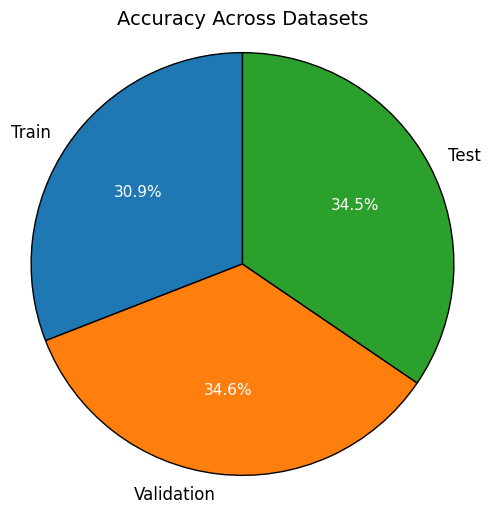

In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import re

csv_log_path = "/kaggle/working/training_log.csv"
df_log = pd.read_csv(csv_log_path)

df_log = df_log.rename(columns={
    "Train Acc": "Train Accuracy (%)",
    "Val Acc": "Val Accuracy (%)"
})

try:
    last_train_acc = df_log[df_log["Epoch"] != "TEST"]["Train Accuracy (%)"].dropna().astype(float).iloc[-1]
    last_val_acc = df_log[df_log["Epoch"] != "TEST"]["Val Accuracy (%)"].dropna().astype(float).iloc[-1]
except:
    last_train_acc = 0.0
    last_val_acc = 0.0

accuracy_path = "/kaggle/working/accuracy0.txt"
test_acc = 0.0
if os.path.exists(accuracy_path):
    with open(accuracy_path, "r", encoding="utf-8") as f:
        match = re.search(r"Accuracy: (\d+\.\d+)", f.readline())
        test_acc = float(match.group(1)) if match else 0.0

labels = ['Train', 'Validation', 'Test']
accuracies = [last_train_acc, last_val_acc, test_acc]
colors = plt.cm.tab10.colors[:3]  

filtered = [(l, a, c) for l, a, c in zip(labels, accuracies, colors) if a > 0]
if not filtered:
    filtered = [('No Data', 1, 'gray')]

labels, accuracies, colors = zip(*filtered)

fig, ax = plt.subplots(figsize=(6, 6))
wedges, texts, autotexts = ax.pie(
    accuracies,
    labels=labels,
    autopct=lambda pct: f'{pct:.1f}%' if pct > 5 else '',
    startangle=90,
    colors=colors,
    wedgeprops={'edgecolor': 'black'}
)

for text in texts:
    text.set_fontsize(12)
for autotext in autotexts:
    autotext.set_fontsize(11)
    autotext.set_color('white')

ax.set_title("Accuracy Across Datasets", fontsize=14)
plt.axis('equal')  


plt.savefig("/kaggle/working/Pie.png", dpi=300)
plt.show()




### 9.3 Classification Report

In [69]:
import os
import torch
from sklearn.metrics import classification_report
from datetime import datetime

true_labels = []
predicted_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        true_labels.extend(labels.cpu().numpy())
        predicted_labels.extend(predictions)

report = classification_report(true_labels, predicted_labels, target_names=["Class 0", "Class 1", "Class 2", "Class 3"])
verbose = False  

if verbose:
    print("📄 Classification Report:\n", report)

report_path = "/kaggle/working/classification_report.txt"
os.makedirs(os.path.dirname(report_path), exist_ok=True)

timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
with open(report_path, "w", encoding="utf-8") as f:
    f.write(f"📌 Classification Report - {timestamp}\n")
    f.write("=" * 50 + "\n")
    f.write(report)
    f.write("\n" + "=" * 50 + "\n")

print(f"✅ Classification report saved to: {report_path}")




✅ Classification report saved to: /kaggle/working/classification_report.txt


In [70]:
import matplotlib.pyplot as plt

data_iter = iter(test_loader)
images, labels = next(data_iter)
images, labels = images.to(device), labels.to(device)
outputs = model(images)
preds = outputs.argmax(dim=1)

plt.figure(figsize=(12, 6))
for idx in range(4):  
    plt.subplot(1, 4, idx+1) 
    img = images[idx].cpu().permute(1, 2, 0).numpy()
    plt.imshow((img * 0.229 + 0.485).clip(0, 1))  
    plt.title(f"True: {labels[idx].item()} / Pred: {preds[idx].item()}")
    plt.axis('off')
plt.tight_layout()
verbose = False  

if verbose:
    plt.show()
else:
    plt.close()  


### 9.4  confusion_matrix

✅ The confusion matrix has been saved at: /kaggle/working/confusion_matrix.png


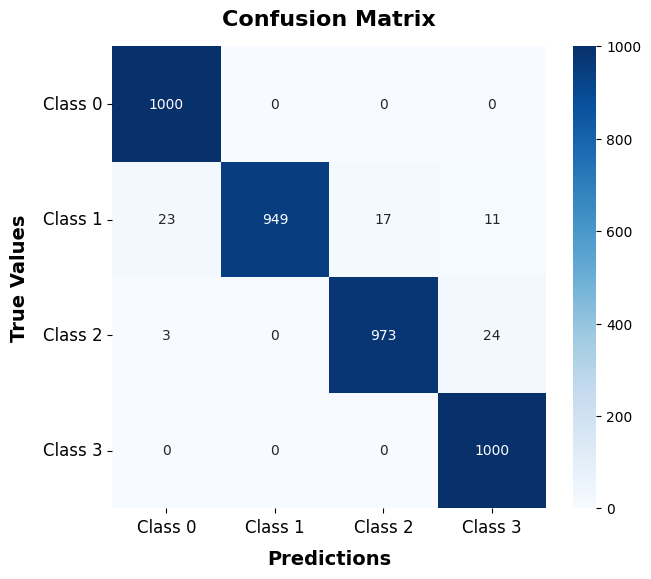

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(true_labels, predicted_labels)

xlabel = "Predictions"
ylabel = "True Values"
title = "Confusion Matrix"

plt.figure(figsize=(7, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", cbar=True,
            xticklabels=["Class 0", "Class 1", "Class 2", "Class 3"],
            yticklabels=["Class 0", "Class 1", "Class 2", "Class 3"])

plt.xlabel(xlabel, fontsize=14, labelpad=10, fontweight="bold")
plt.ylabel(ylabel, fontsize=14, labelpad=10, fontweight="bold")
plt.xticks(rotation=0, fontsize=12)
plt.yticks(rotation=0, fontsize=12)
plt.title(title, fontsize=16, pad=15, fontweight="bold")

conf_matrix_path = "/kaggle/working/confusion_matrix.png"
plt.savefig(conf_matrix_path, dpi=300, bbox_inches="tight")

print(f"✅ The confusion matrix has been saved at: {conf_matrix_path}")
plt.show()
